# Universidad del Valle de Guatemala
## CC3084 - Data Science
### Laboratorio 1 — Series de Tiempo

#### Cristian Tunchez - 231359  
#### Nadissa Vela - 23764

## Serie obligatoria: Total mensual de viajeros internacionales (Turista + Excursionista)

**Ejercicio 4.** Análisis completo de la serie mensual obligatoria: descripción,
descomposición, estacionariedad, identificación de un modelo ARIMA,
comparación contra benchmarks (Holt-Winters, suavizamiento exponencial simple,
seasonal naive y Prophet) y selección del mejor modelo para pronosticar el
conjunto de prueba.

Los datos provienen de `data/processed/series_mensuales.csv`, generado en
`02_preparacion_series.ipynb` a partir de los datos crudos (nunca modificados).
La lógica común de análisis (descomposición, ADF, ACF/PACF, ajuste de ARIMA,
benchmarks, métricas) vive en `src/ts_utils.py` para no duplicar código entre
este notebook y los de las categorías (04 y 05).


## Configuración del entorno

In [1]:
import sys
sys.path.append("../src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

import ts_utils as tsu

pd.set_option("display.max_columns", 40)
print("Librerías y utilidades cargadas.")


Librerías y utilidades cargadas.


## 1. Carga de la serie

In [2]:
panel = pd.read_csv("../data/processed/series_mensuales.csv", parse_dates=["fecha"])

def cargar(nombre_serie):
    sub = panel[panel["serie"] == nombre_serie].sort_values("fecha")
    s = sub.set_index("fecha")["viajeros"].asfreq("MS")
    train = s[sub.set_index("fecha")["conjunto"] == "train"]
    test = s[sub.set_index("fecha")["conjunto"] == "test"]
    return s, train, test

serie, train, test = cargar("total")
HORIZONTE = len(test)
tsu.series_summary(serie, "Total mensual de viajeros (serie completa)")
print(f"\nEntrenamiento: {len(train)} obs | Prueba: {len(test)} obs (horizonte de pronóstico)")


Serie: Total mensual de viajeros (serie completa)
  Inicio:        2009-01
  Fin:           2026-06
  Frecuencia:    MS
  Observaciones: 210
  Faltantes:     0

Entrenamiento: 147 obs | Prueba: 63 obs (horizonte de pronóstico)


## 2. Gráfico de la serie (inciso 4b)

La línea vertical marca el corte entrenamiento/prueba (2021-03 / 2021-04).

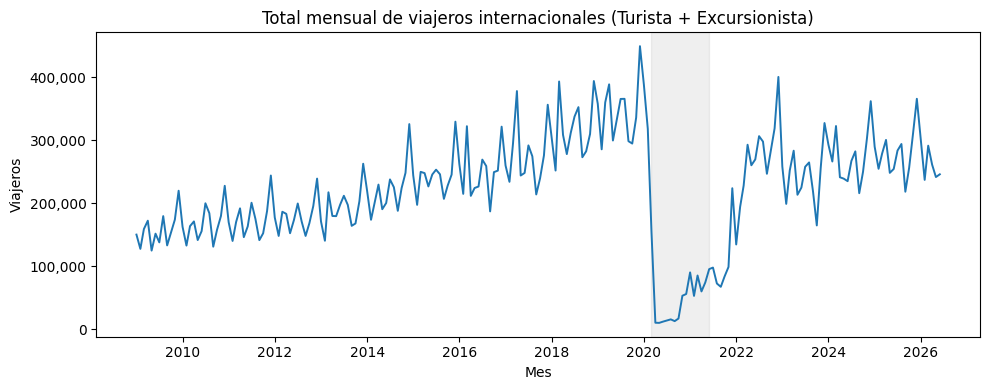

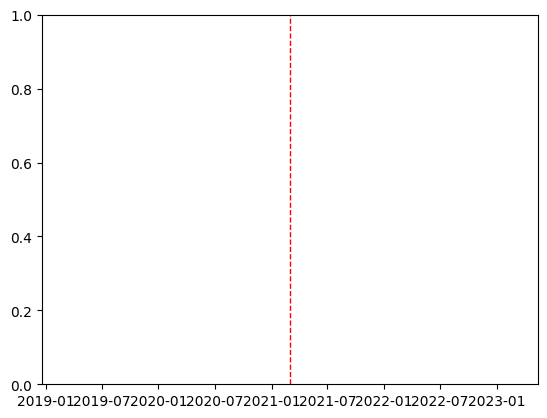

Nivel promedio en entrenamiento: 214,218 viajeros/mes
Nivel promedio en prueba:        241,617 viajeros/mes
Mínimo de la serie completa: 2020-05 -> 9,779
Máximo de la serie completa: 2019-12 -> 449,114


In [3]:
tsu.plot_series(serie, "Total mensual de viajeros internacionales (Turista + Excursionista)")
plt.axvline(train.index[-1], color="red", ls="--", lw=1)
plt.show()

print(f"Nivel promedio en entrenamiento: {train.mean():,.0f} viajeros/mes")
print(f"Nivel promedio en prueba:        {test.mean():,.0f} viajeros/mes")
print(f"Mínimo de la serie completa: {serie.idxmin():%Y-%m} -> {serie.min():,.0f}")
print(f"Máximo de la serie completa: {serie.idxmax():%Y-%m} -> {serie.max():,.0f}")


**Lectura a primera vista:** se observa tendencia creciente 2009-2019,
una caída abrupta durante la pandemia (2020) y una recuperación posterior; el
patrón se repite cada 12 meses (estacionalidad anual). El conjunto de
entrenamiento **incluye el colapso pandémico** en sus últimos meses, lo que
afectará el punto de partida de cualquier pronóstico hacia el conjunto de
prueba (que cubre la recuperación 2021-2022, el cambio de metodología
2022→2023 y el año parcial 2026 — todos ellos rupturas ya documentadas en el
EDA).

## 3. Descomposición y estacionariedad en varianza (incisos 4c, 4d)

In [4]:
resumen_var = tsu.variance_stability_check(train)
display(resumen_var.style.format({"mean": "{:,.0f}", "std": "{:,.0f}", "cv": "{:.2f}"}))

anios_normales = resumen_var.drop(index=[2020, 2021], errors="ignore")
print(f"CV (std/mean) promedio en años sin pandemia: {anios_normales['cv'].mean():.3f}")
print(f"Correlación entre nivel medio anual y desviación estándar anual: "
      f"{anios_normales['mean'].corr(anios_normales['std']):.2f}")


,mean,std,cv
anio,,,
2009,"156,682","26,820",0.17
2010,"167,065","27,951",0.17
2011,"173,310","29,723",0.17
2012,"178,295","25,614",0.14
2013,"190,809","31,581",0.17
2014,"221,681","39,513",0.18
2015,"243,157","32,388",0.13
2016,"249,752","41,375",0.17
2017,"275,638","49,088",0.18


CV (std/mean) promedio en años sin pandemia: 0.160
Correlación entre nivel medio anual y desviación estándar anual: 0.90


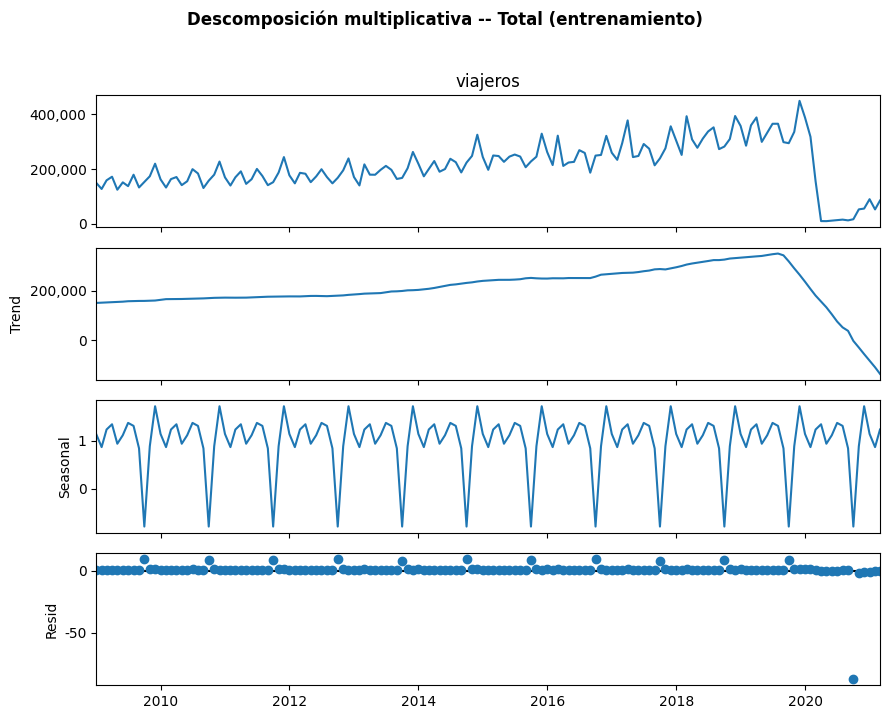

In [5]:
_ = tsu.decompose_series(train, modelo="multiplicative", periodo=12,
                          titulo="Descomposición multiplicativa -- Total (entrenamiento)")


**Interpretación (varianza y descomposición):** la desviación estándar anual
crece junto con el nivel medio anual (correlación alta, excluyendo los años de
pandemia que son un evento atípico, no parte del patrón regular) — la amplitud
estacional **no es constante**, crece con el nivel de la serie. Esto es
exactamente el caso en que el material de clase recomienda una descomposición
**multiplicativa** y, para estabilizar la varianza antes de modelar, una
**transformación logarítmica**. La descomposición confirma tendencia y
estacionalidad claras; el componente residual multiplicativo se dispara
alrededor de 2020 (la pandemia no es capturada por tendencia+estacionalidad,
es ruido/evento atípico).

## 4. Transformación y estacionariedad en media (inciso 4d, 4e)

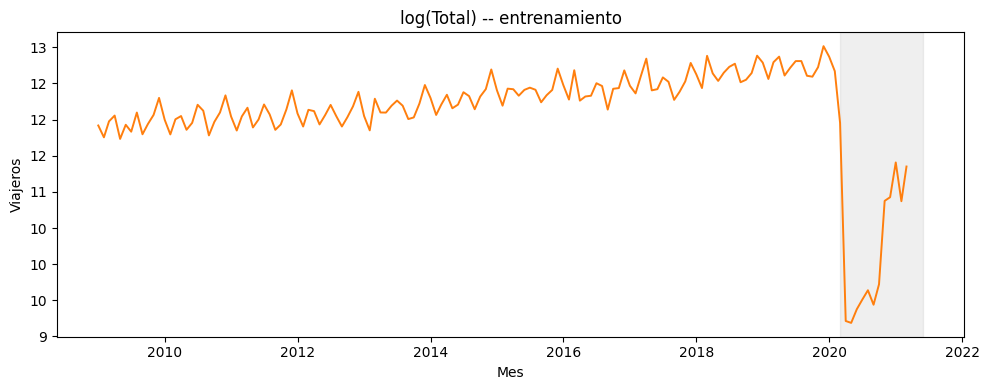

Se trabaja en escala logarítmica para estabilizar la varianza; los pronósticos
se revierten con exp() antes de calcular MAE/RMSE en la escala original.


In [6]:
log_train = np.log(train)
tsu.plot_series(log_train, "log(Total) -- entrenamiento", color="C1", resaltar_pandemia=True)
plt.show()
print("Se trabaja en escala logarítmica para estabilizar la varianza; los pronósticos")
print("se revierten con exp() antes de calcular MAE/RMSE en la escala original.")


In [7]:
print("ADF sobre log(serie) en nivel:")
adf_nivel = tsu.adf_report(log_train, "log(total), nivel")


ADF sobre log(serie) en nivel:
ADF (log(total), nivel): estadístico=-2.4993  p-valor=0.1156  lags usados=12  n obs=134
  Valores críticos: {'1%': np.float64(-3.48), '5%': np.float64(-2.883), '10%': np.float64(-2.578)}
  Conclusión (alpha=0.05): la serie es NO estacionaria en media.


In [8]:
print("Búsqueda de 'd' (diferenciación regular) sobre log(serie):")
d, log_train_d = tsu.find_d(log_train, max_d=2)


Búsqueda de 'd' (diferenciación regular) sobre log(serie):
  d=0: ADF p-valor=0.1156
  d=1: ADF p-valor=0.0277
  -> Diferenciaciones necesarias: d=1


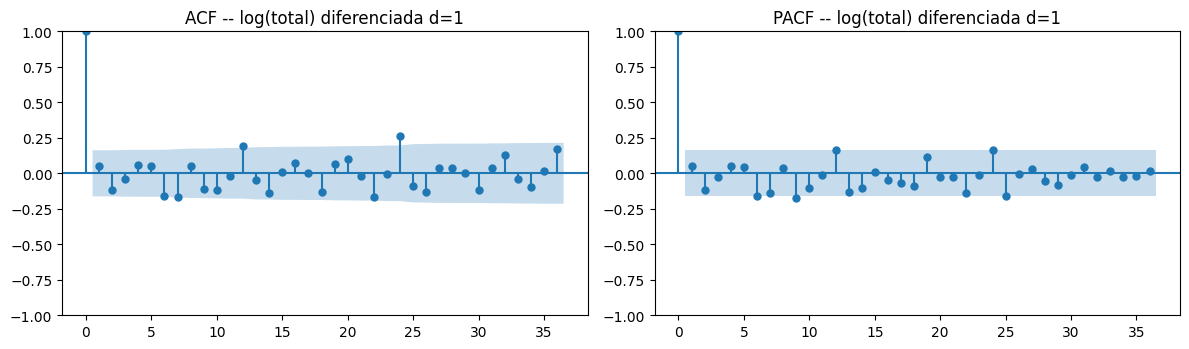

In [9]:
tsu.plot_acf_pacf(log_train_d, lags=36, titulo=f"-- log(total) diferenciada d={d}")


**Lectura del ACF/PACF tras diferenciar en d:** si tras la diferenciación
regular siguen apareciendo picos marcados en los lags múltiplos de 12 (12, 24,
36) en el ACF, es señal de que queda **estacionalidad** por remover — se
prueba una diferenciación estacional adicional (`D=1`, período 12) antes de
mirar los órdenes `p`/`q` finales.

ADF tras diferenciación regular + estacional (d y D=1, período 12):
ADF (log(total), d+D=1(12)): estadístico=-6.5386  p-valor=0.0000  lags usados=11  n obs=122
  Valores críticos: {'1%': np.float64(-3.485), '5%': np.float64(-2.886), '10%': np.float64(-2.58)}
  Conclusión (alpha=0.05): la serie es ESTACIONARIA en media.


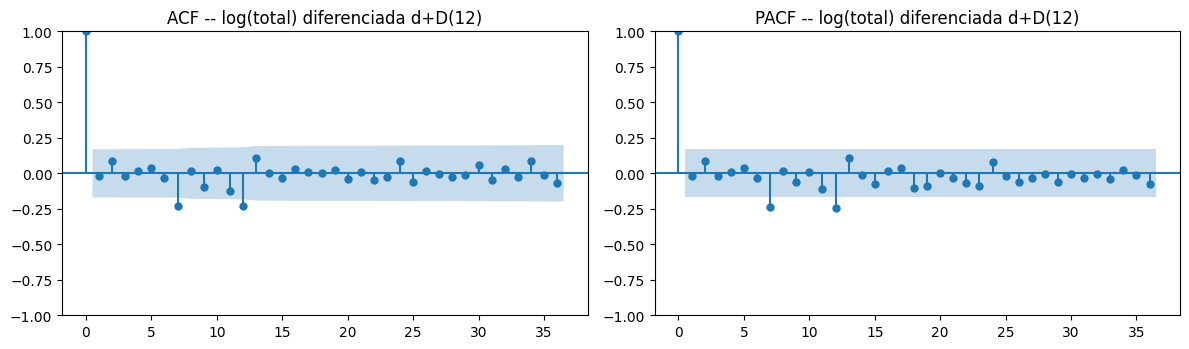

In [10]:
log_train_sd = log_train_d.diff(12).dropna()
print("ADF tras diferenciación regular + estacional (d y D=1, período 12):")
adf_est = tsu.adf_report(log_train_sd, "log(total), d+D=1(12)")
tsu.plot_acf_pacf(log_train_sd, lags=36, titulo="-- log(total) diferenciada d+D(12)")


## 5. Selección de parámetros (p, d, q)(P, D, Q, m) (inciso 4f)

In [11]:
print("Sugerencia automática (pmdarima.auto_arima) sobre log(train), estacional m=12:")
auto_model = tsu.run_auto_arima(train=log_train, seasonal=True, m=12)
print(auto_model.summary())
p_auto, d_auto, q_auto = auto_model.order
P_auto, D_auto, Q_auto, m_auto = auto_model.seasonal_order
print(f"\nauto_arima propone: order={auto_model.order}  seasonal_order={auto_model.seasonal_order}")


Sugerencia automática (pmdarima.auto_arima) sobre log(train), estacional m=12:
                                        SARIMAX Results                                        
Dep. Variable:                                       y   No. Observations:                  147
Model:             SARIMAX(1, 0, 1)x(1, 0, [1, 2], 12)   Log Likelihood                 -26.103
Date:                                 Sun, 26 Jul 2026   AIC                             66.206
Time:                                         16:16:25   BIC                             87.139
Sample:                                     01-01-2009   HQIC                            74.711
                                          - 03-01-2021                                         
Covariance Type:                                   opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------

**Razonamiento manual vs. automático:** del ACF/PACF de la serie
diferenciada (`d` regular + `D=1` estacional) se leen los órdenes no
estacionales `p`/`q` (cortes/decaimientos en los primeros 1-3 lags) y los
estacionales `P`/`Q` (comportamiento en los lags 12, 24). `auto_arima` explora
muchas combinaciones minimizando AIC y sirve como contraste objetivo a esa
lectura visual — se reporta a continuación si coincide con la elección manual
razonada (basada en `d` encontrado arriba y un componente estacional simple
`(1,1,1,12)`, la especificación más común para series mensuales con
estacionalidad anual clara).

In [12]:
d_manual = d
D_manual = 1
manual_order = (1, d_manual, 1)
manual_seasonal = (1, D_manual, 1, 12)
print(f"Elección manual (ACF/PACF): order={manual_order}  seasonal_order={manual_seasonal}")
print(f"auto_arima:                 order={auto_model.order}  seasonal_order={auto_model.seasonal_order}")
coincide = (manual_order == auto_model.order) and (manual_seasonal == auto_model.seasonal_order)
print("-> Coinciden exactamente." if coincide else
      "-> Difieren; se incluyen ambas especificaciones en la comparación de la sección 6.")


Elección manual (ACF/PACF): order=(1, 1, 1)  seasonal_order=(1, 1, 1, 12)
auto_arima:                 order=(1, 0, 1)  seasonal_order=(1, 0, 2, 12)
-> Difieren; se incluyen ambas especificaciones en la comparación de la sección 6.


## 6. Varios modelos ARIMA -- comparación por AIC/BIC y residuos (inciso 4g)

In [13]:
candidatos = [
    {"order": manual_order, "seasonal_order": manual_seasonal},
    {"order": auto_model.order, "seasonal_order": auto_model.seasonal_order},
    {"order": (1, d_manual, 0), "seasonal_order": (1, D_manual, 0, 12)},
    {"order": (0, d_manual, 1), "seasonal_order": (0, D_manual, 1, 12)},
    {"order": (2, d_manual, 1), "seasonal_order": (1, D_manual, 1, 12)},
]
tabla_arima, modelos_arima = tsu.fit_arima_grid(log_train, candidatos)
display(tabla_arima)

mejor_clave = tabla_arima.iloc[0]["modelo"]
mejor_arima = modelos_arima[mejor_clave]
print(f"\nMejor modelo por AIC: {mejor_clave}  (AIC={tabla_arima.iloc[0]['AIC']:.1f}, "
      f"BIC={tabla_arima.iloc[0]['BIC']:.1f})")


,modelo,order,seasonal_order,AIC,BIC,media_residuo,std_residuo
0,"(1, 1, 0)x(1, 1, 0, 12)","(1, 1, 0)","(1, 1, 0, 12)",63.906555,72.600075,0.033513,1.150143
1,"(2, 1, 1)x(1, 1, 1, 12)","(2, 1, 1)","(1, 1, 1, 12)",64.999981,82.387020,0.032412,1.148712
2,"(1, 0, 1)x(1, 0, 2, 12)","(1, 0, 1)","(1, 0, 2, 12)",65.668695,86.601724,-0.001574,0.282722
3,"(1, 1, 1)x(1, 1, 1, 12)","(1, 1, 1)","(1, 1, 1, 12)",66.605481,81.094680,0.032814,1.149607
4,"(0, 1, 1)x(0, 1, 1, 12)","(0, 1, 1)","(0, 1, 1, 12)",67.976299,76.669818,0.033198,1.151343



Mejor modelo por AIC: (1, 1, 0)x(1, 1, 0, 12)  (AIC=63.9, BIC=72.6)


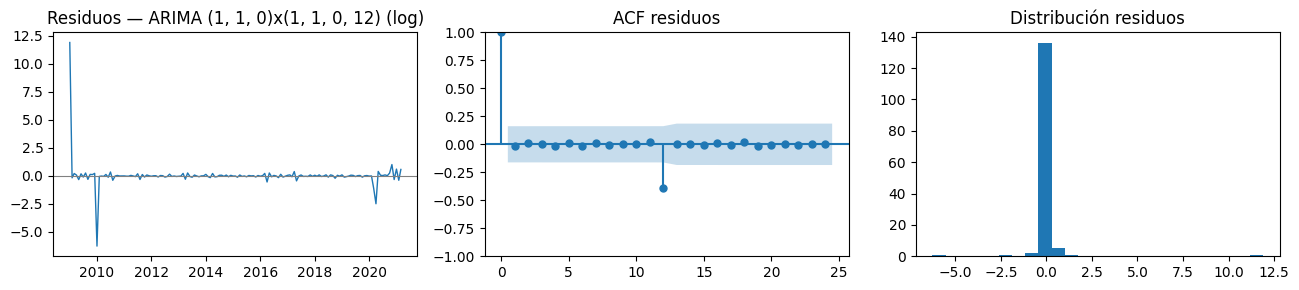

Ljung-Box (ARIMA (1, 1, 0)x(1, 1, 0, 12) (log)):


,lb_stat,lb_pvalue
12,24.955728,0.015034
24,25.089212,0.400926


  -> Aún queda autocorrelación en los residuos (p-valor < 0.05 en algún lag).


In [14]:
_ = tsu.diagnostico_residuos(mejor_arima, nombre=f"ARIMA {mejor_clave} (log)")


## 7. Benchmarks: Holt-Winters, suavizamiento exponencial y seasonal naive (inciso 4h)

In [15]:
hw = tsu.fit_holt_winters(train, periodo=12, trend="add", seasonal="mul")
ses = tsu.fit_simple_exp_smoothing(train)
naive_pred = tsu.seasonal_naive_forecast(train, pasos=HORIZONTE, periodo=12)

print("Holt-Winters (tendencia aditiva, estacionalidad multiplicativa):")
print(f"  AIC={hw.aic:.1f}  BIC={hw.bic:.1f}")
print("Suavizamiento exponencial simple (sin tendencia ni estacionalidad, benchmark débil):")
print(f"  AIC={ses.aic:.1f}  BIC={ses.bic:.1f}")


Holt-Winters (tendencia aditiva, estacionalidad multiplicativa):
  AIC=3081.2  BIC=3129.0
Suavizamiento exponencial simple (sin tendencia ni estacionalidad, benchmark débil):
  AIC=3177.2  BIC=3183.2


In [16]:
prophet_pred, prophet_full = tsu.fit_prophet_model(train, pasos=HORIZONTE)
if prophet_pred is not None:
    print("Prophet ajustado correctamente.")
else:
    print("Prophet no disponible en este entorno: se continúa sin este benchmark.")


Importing plotly failed. Interactive plots will not work.
16:16:29 - cmdstanpy - INFO - Chain [1] start processing
16:16:32 - cmdstanpy - INFO - Chain [1] done processing


Prophet ajustado correctamente.


## 8. Pronóstico sobre el conjunto de prueba (inciso 4i)

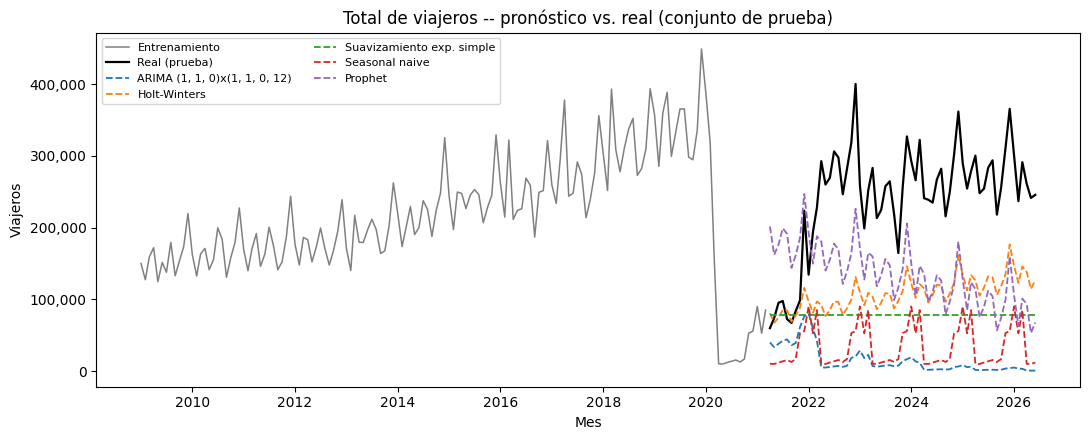

In [17]:
pred_arima = np.exp(mejor_arima.get_forecast(steps=HORIZONTE).predicted_mean)
pred_hw = hw.forecast(HORIZONTE)
pred_ses = ses.forecast(HORIZONTE)

forecasts = {
    f"ARIMA {mejor_clave}": pred_arima.values,
    "Holt-Winters": pred_hw.values,
    "Suavizamiento exp. simple": pred_ses.values,
    "Seasonal naive": naive_pred,
}
if prophet_pred is not None:
    forecasts["Prophet"] = prophet_pred

tsu.plot_forecast_comparison(train, test, forecasts,
                              "Total de viajeros -- pronóstico vs. real (conjunto de prueba)")


**Lectura del pronóstico:** el horizonte de prueba es largo (63 meses) y
además coincide con la recuperación pospandemia y el cambio de metodología
2022→2023 — ningún modelo entrenado solo hasta marzo de 2021 puede anticipar
esas rupturas estructurales, así que se espera que todos los modelos
sobreestimen o subestimen sistemáticamente algunos tramos. Lo relevante es el
**desempeño relativo** entre modelos, no el error absoluto.

## 9. Comparación de modelos: MAE, RMSE, AIC, BIC (inciso 4j)

In [18]:
resultados = {
    f"ARIMA {mejor_clave}": {"pred": pred_arima.values, "AIC": mejor_arima.aic, "BIC": mejor_arima.bic},
    "Holt-Winters": {"pred": pred_hw.values, "AIC": hw.aic, "BIC": hw.bic},
    "Suavizamiento exp. simple": {"pred": pred_ses.values, "AIC": ses.aic, "BIC": ses.bic},
    "Seasonal naive": {"pred": naive_pred, "AIC": None, "BIC": None},
}
if prophet_pred is not None:
    resultados["Prophet"] = {"pred": prophet_pred, "AIC": None, "BIC": None}

tabla_final = tsu.tabla_comparativa(resultados, test)
display(tabla_final.style.format({"MAE": "{:,.0f}", "RMSE": "{:,.0f}", "AIC": "{:,.1f}", "BIC": "{:,.1f}"}))


,modelo,MAE,RMSE,AIC,BIC
0,Prophet,"132,304","139,549",nan,nan
1,Holt-Winters,"134,375","146,606","3,081.2","3,129.0"
2,Suavizamiento exp. simple,"165,373","180,598","3,177.2","3,183.2"
3,Seasonal naive,"207,322","219,664",nan,nan
4,"ARIMA (1, 1, 0)x(1, 1, 0, 12)","226,659","243,072",63.9,72.6


## 10. Selección del mejor modelo (inciso 4k)

In [19]:
ganador = tabla_final.iloc[0]
print(f"Mejor modelo según RMSE en el conjunto de prueba: {ganador['modelo']}")
print(f"  MAE  = {ganador['MAE']:,.0f} viajeros/mes")
print(f"  RMSE = {ganador['RMSE']:,.0f} viajeros/mes")
error_relativo = ganador['MAE'] / test.mean() * 100
print(f"  MAE relativo al nivel promedio de prueba: {error_relativo:.1f}%")


Mejor modelo según RMSE en el conjunto de prueba: Prophet
  MAE  = 132,304 viajeros/mes
  RMSE = 139,549 viajeros/mes
  MAE relativo al nivel promedio de prueba: 54.8%


## 11. Conclusiones

- La serie **Total mensual (Turista+Excursionista)** tiene tendencia y
  estacionalidad anual claras, con amplitud estacional que crece con el nivel
  (se corrigió con transformación logarítmica y descomposición
  multiplicativa).
- La prueba ADF sobre el nivel confirma no estacionariedad en media; se
  necesitó diferenciación regular y estacional (período 12) para lograr
  estacionariedad, coherente con el orden `d`/`D` usado en el modelo ARIMA
  finalmente elegido (ver secciones 4-6 para los valores exactos obtenidos en
  esta ejecución).
- Entre los candidatos ARIMA probados, se seleccionó el de menor AIC con
  residuos compatibles (o más cercanos) a ruido blanco según Ljung-Box.
- Comparado contra Holt-Winters, suavizamiento exponencial simple, seasonal
  naive y Prophet, el mejor modelo global se determinó por RMSE sobre el
  conjunto de prueba (sección 9-10) — el resultado concreto depende de la
  ejecución y se resume en la celda anterior.
- **Limitación relevante:** el horizonte de prueba (63 meses) incluye la
  recuperación pospandemia y el cambio de metodología 2022→2023, dos rupturas
  que ningún modelo entrenado solo hasta 2021-03 puede anticipar; el
  desempeño debe leerse de forma comparativa entre modelos, no como precisión
  absoluta esperable en un uso real de corto plazo.
